# Telco Customer Churn

Looking at what is linked to customers leaving (churn) using **telco_clean.csv**.
In the data, **Churn = 1** means the customer left and **Churn = 0** means they stayed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("telco_clean.csv")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Overall churn rate. Averaging the 0/1 **Churn** column gives the share of customers who left.

In [2]:
overall = df["Churn"].mean() * 100
print("Overall churn rate:", round(overall, 1), "%")

Overall churn rate: 26.6 %


## Chart 1: Churn by contract type

This chart shows that month-to-month customers churn far more (42.7%) than one-year (11.3%) or two-year (2.8%) customers.

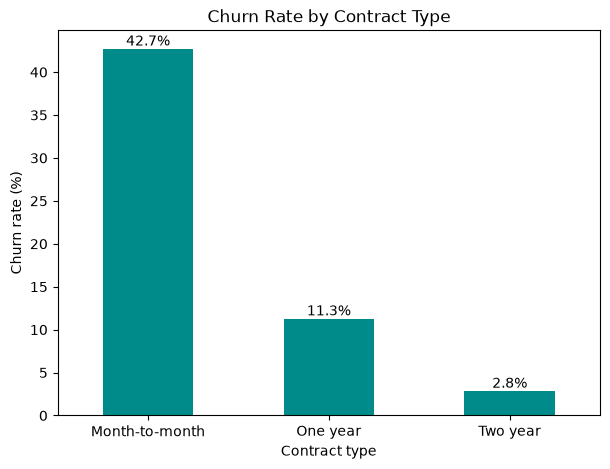

In [3]:
contract = df.groupby("Contract")["Churn"].mean() * 100
contract = contract[["Month-to-month", "One year", "Two year"]]

ax = contract.plot(kind="bar", color="darkcyan", figsize=(7, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

## Chart 2: Churn by tenure

This chart shows that churn is highest for customers in their first year (47.7%) and keeps falling the longer they stay, down to 6.6% after 5 years.

Tenure is in months, so I grouped it into 12-month bands first.

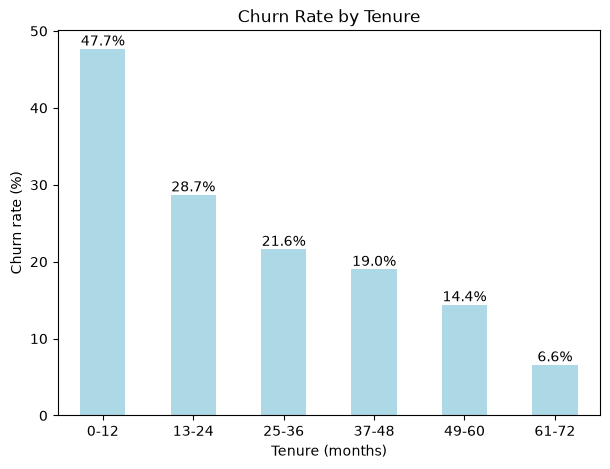

In [4]:
df["tenure_band"] = pd.cut(df["tenure"],
bins=[0, 12, 24, 36, 48, 60, 72],
labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])

tenure = df.groupby("tenure_band")["Churn"].mean() * 100

ax = tenure.plot(kind="bar", color="lightblue", figsize=(7, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

## Chart 3: Churn by monthly charges

This chart shows that customers who churned paid more per month on average ($74.44) than customers who stayed ($61.31).

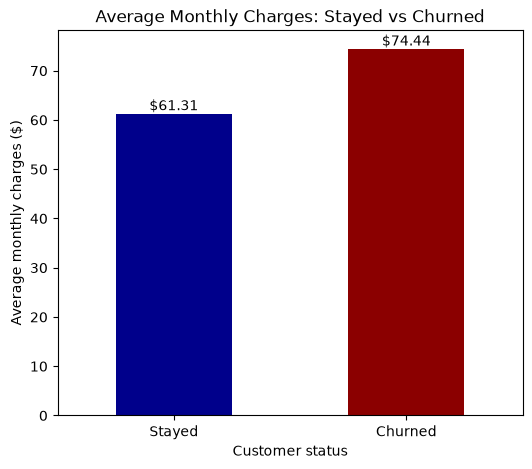

In [5]:
charges = df.groupby("Churn")["MonthlyCharges"].mean()
charges.index = ["Stayed", "Churned"]

ax = charges.plot(kind="bar", color=["darkblue", "darkred"], figsize=(6, 5))
ax.bar_label(ax.containers[0], fmt="$%.2f")
plt.title("Average Monthly Charges: Stayed vs Churned")
plt.xlabel("Customer status")
plt.ylabel("Average monthly charges ($)")
plt.xticks(rotation=0)
plt.show()

## Chart 4: Churn by payment method

This chart shows that customers who pay by electronic check churn the most (45.3%), while the other three methods are all between 15.3% and 19.2%.

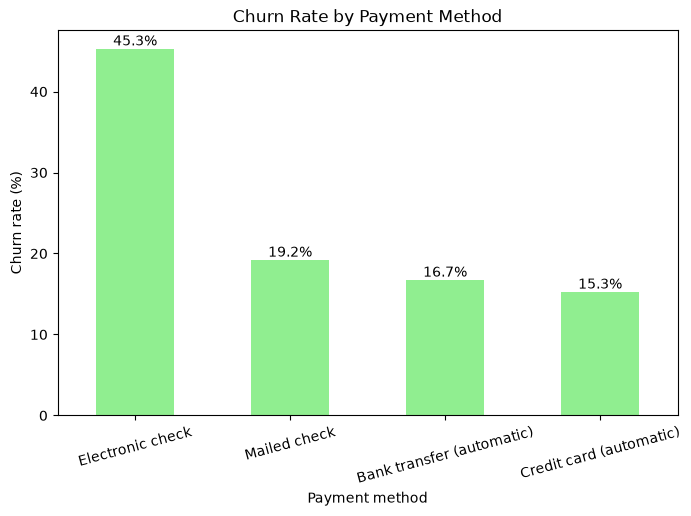

In [6]:
payment = df.groupby("PaymentMethod")["Churn"].mean() * 100
payment = payment.sort_values(ascending=False)

ax = payment.plot(kind="bar", color="lightgreen", figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=15)
plt.show()

## Chart 5: Churn by internet service

This chart shows that fiber optic customers churn the most (41.9%), compared with 19.0% for DSL and 7.4% for customers with no internet service.

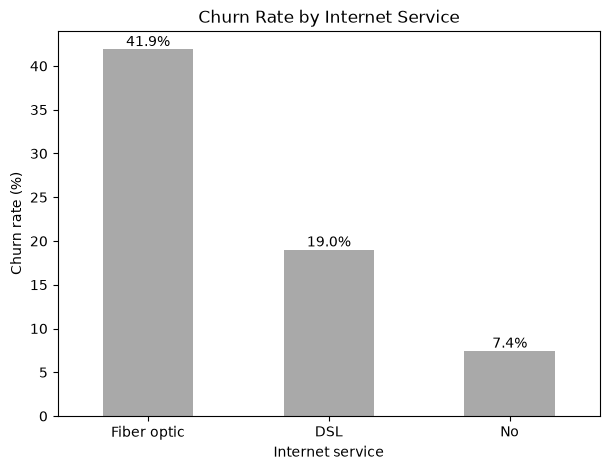

In [7]:
internet = df.groupby("InternetService")["Churn"].mean() * 100
internet = internet[["Fiber optic", "DSL", "No"]]

ax = internet.plot(kind="bar", color="darkgrey", figsize=(7, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet service")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

## Summary

Overall about 26.6% of customers churned. Churn was highest for:
- month-to-month contracts
- new customers (first year)
- customers with higher monthly charges
- customers paying by electronic check
- fiber optic internet customers

These are links in the data, not proof of what causes churn, and some of them overlap (for example, new customers are often on month-to-month contracts).